# Summative Lab - Analytics Firm Clients: Customer Reviews Analysis

Three parts on one dataset of Amazon customer reviews (`amazon_reviews_lab.csv`):
1. **NLP** - clean review text, find frequent words and bigrams
2. **Time Series** - review volume and ratings over time (stationarity, ARIMA forecast)
3. **Neural Networks** - predict the star rating from review text

# Part 1 : NLP

In [317]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter


# For text preprocessing
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import bigrams


# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptr

True

In [318]:
# load and explore dataset
df = pd.read_csv('amazon_reviews_lab.csv')
print(df.shape)
df.head()

(997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [319]:
# columns
df.columns

Index(['product_id', 'rating', 'review_text', 'review_summary',
       'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label',
       'review_length_words'],
      dtype='object')

In [320]:
df['rating'].value_counts().sort_index()

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

In [321]:
# data types
df.dtypes

product_id              object
rating                   int64
review_text             object
review_summary          object
review_time_raw         object
unix_review_time       float64
timestamp               object
sentiment_label         object
review_length_words      int64
dtype: object

In [322]:
display(df[['rating', 'review_text', 'sentiment_label']].head(5))

,rating,review_text,sentiment_label
0,2,This film is definitely not for anyone who is ...,negative
1,5,This movie was playing at Radio City Music Hal...,positive
2,1,I would love to buy this movie as I have been ...,negative
3,1,The advertisment for this DVD on Amazon was in...,negative
4,5,I bought some of these to try with a light usi...,positive


In [323]:
# missing values
df.isnull().sum()

product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

In [324]:
# duplicates
df.duplicated().sum()

np.int64(0)

In [325]:
# summary statistics
df.describe()

,rating,unix_review_time,review_length_words
count,997.000000,9.970000e+02,997.000000
mean,4.129388,1.344766e+09,146.374122
std,1.280181,4.411420e+07,216.126770
min,1.000000,9.580896e+08,5.000000
25%,4.000000,1.311898e+09,32.000000
50%,5.000000,1.356048e+09,67.000000
75%,5.000000,1.379462e+09,165.000000
max,5.000000,1.405555e+09,2079.000000


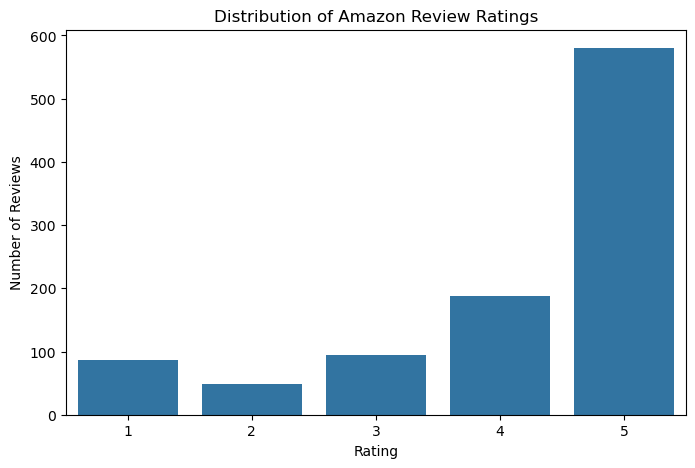

In [326]:
# Distribution of customer ratings
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='rating')

plt.title('Distribution of Amazon Review Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()


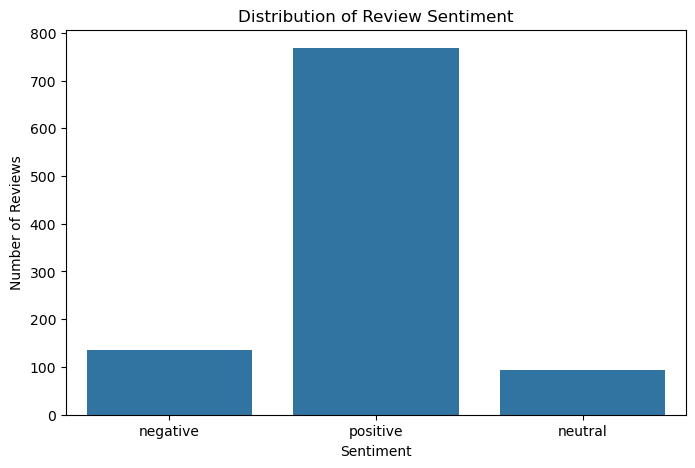

In [327]:
# sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment_label')

plt.title('Distribution of Review Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

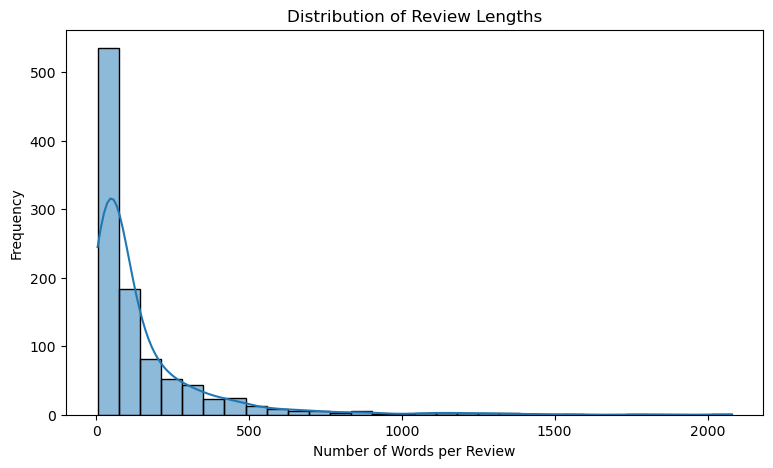

In [328]:
# review length distribution
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='review_length_words', bins=30, kde=True)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words per Review')
plt.ylabel('Frequency')
plt.show()

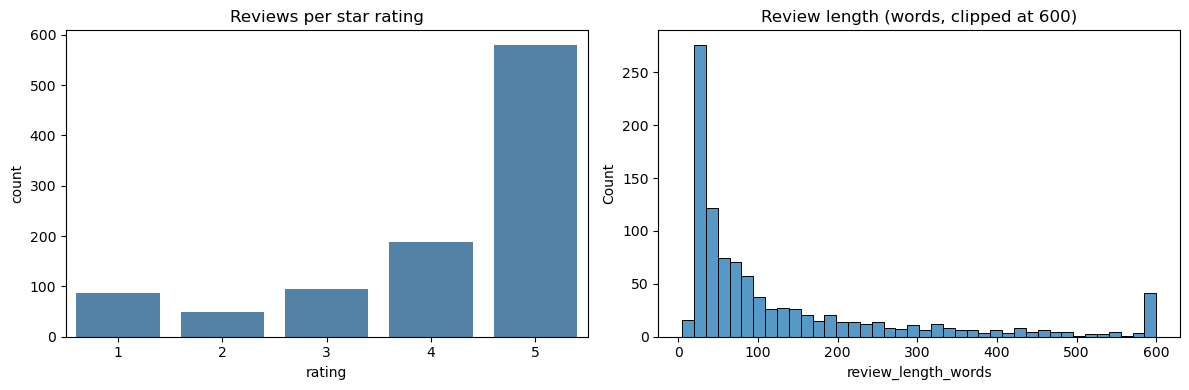

count     997.000000
mean      146.374122
std       216.126770
min         5.000000
25%        32.000000
50%        67.000000
75%       165.000000
max      2079.000000
Name: review_length_words, dtype: float64
Empty reviews: 0


In [329]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='rating', data=df, ax=ax[0], color='steelblue'); ax[0].set_title('Reviews per star rating')
sns.histplot(df['review_length_words'].clip(upper=600), bins=40, ax=ax[1]); ax[1].set_title('Review length (words, clipped at 600)')
plt.tight_layout(); plt.show()
print(df['review_length_words'].describe())
print("Empty reviews:", (df['review_text'].str.strip() == '').sum())

In [330]:
# Preprocessing
stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor'}
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()                                          # 1. lowercase
    text = re.sub(r'http\S+|www\.\S+', ' ', text)                     # 2. remove URLs
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))  # 3. remove punctuation
    tokens = word_tokenize(text)                                      # 4. tokenize
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]        # 5. alphabetic only (2+ letters so 'no' survives)
    tokens = [t for t in tokens if t not in stop_words]               # 6. stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]                # 7. lemmatize
    return tokens                                                     # 8. cleaned tokens

df['processed_tokens'] = df['review_text'].apply(preprocess_text)
df['processed_text'] = df['processed_tokens'].apply(' '.join)

i = 5
print("RAW  :", df['review_text'].iloc[i][:300])
print("CLEAN:", df['processed_text'].iloc[i][:300])

RAW  : For the money you can't go wrong. Yes, it has a litlle play in the mechanism but, you can adjust your mounting to accomodate that. It works great and frees up counter space. I would do it all again. Why spend 3 times more.
CLEAN: money go wrong yes litlle play mechanism adjust mounting accomodate work great free counter space would spend time


In [331]:
# validate preprocessing
raw_vocab = set(w for t in df['review_text'] for w in re.findall(r'[a-z]+', t.lower()))
clean_vocab = set(w for toks in df['processed_tokens'] for w in toks)
print(f"Vocabulary: {len(raw_vocab):,} raw -> {len(clean_vocab):,} cleaned "
      f"({100 * (1 - len(clean_vocab) / len(raw_vocab)):.1f}% smaller)")
print("Avg tokens per review: raw", round(df['review_length_words'].mean(), 1),
      "-> cleaned", round(df['processed_tokens'].str.len().mean(), 1))
print("Stopwords left in vocabulary:", len([w for w in clean_vocab if w in stop_words]))
print("Reviews that became empty after cleaning:", (df['processed_tokens'].str.len() == 0).sum())

Vocabulary: 7,532 raw -> 6,563 cleaned (12.9% smaller)
Avg tokens per review: raw 146.4 -> cleaned 73.0
Stopwords left in vocabulary: 9
Reviews that became empty after cleaning: 0


In [332]:
# word and bigram frequencies
all_tokens = [t for toks in df['processed_tokens'] for t in toks]
word_counts = Counter(all_tokens)
top_words = word_counts.most_common(20)
print("Top 20 words:", top_words)

all_bigrams = [b for toks in df['processed_tokens'] for b in bigrams(toks)]
bigram_counts = Counter(all_bigrams)
top_bigrams = bigram_counts.most_common(20)
print("\nTop 20 bigrams:")
for b, c in top_bigrams: print(f"  {' '.join(b):25s} {c}")

Top 20 words: [('nook', 1577), ('not', 1064), ('book', 986), ('one', 596), ('kindle', 590), ('screen', 535), ('like', 474), ('read', 464), ('work', 463), ('great', 444), ('tablet', 443), ('use', 432), ('tv', 427), ('get', 426), ('no', 408), ('device', 399), ('would', 383), ('good', 348), ('reader', 346), ('well', 336)]

Top 20 bigrams:
  barnes noble              166
  nook color                135
  battery life              98
  touch screen              96
  sd card                   89
  nook hd                   80
  work great                65
  nook tablet               64
  kindle fire               61
  work well                 59
  read book                 58
  no problem                53
  wall mount                53
  wi fi                     47
  simple touch              45
  customer service          41
  android tablet            40
  micro sd                  39
  original nook             38
  nook simple               37


In [333]:
from nltk.util import trigrams
trigram_counts = Counter(t for toks in df['processed_tokens'] for t in trigrams(toks))
for t, c in trigram_counts.most_common(15):
    print(f"  {' '.join(t):30s} {c}")

  nook simple touch              37
  micro sd card                  28
  barnes noble nook              14
  barnes noble store             11
  sd card slot                   10
  adobe digital edition          10
  google play store              9
  book barnes noble              8
  tv wall mount                  8
  access google play             8
  kindle fire hd                 8
  acer aspire one                7
  not big deal                   7
  access android market          7
  micro usb cable                7


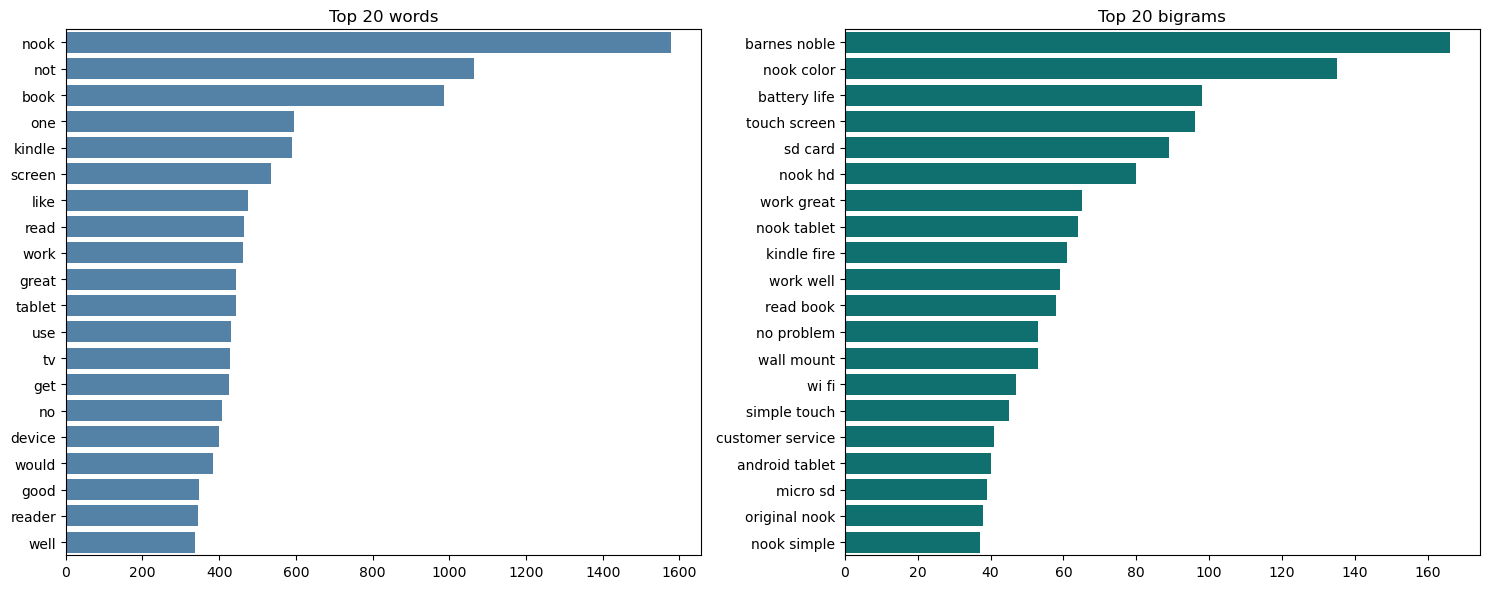

In [334]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
w, c = zip(*top_words)
sns.barplot(x=list(c), y=list(w), ax=ax[0], color='steelblue'); ax[0].set_title('Top 20 words')
b, c = zip(*top_bigrams)
sns.barplot(x=list(c), y=[' '.join(x) for x in b], ax=ax[1], color='teal'); ax[1].set_title('Top 20 bigrams')
plt.tight_layout(); plt.show()

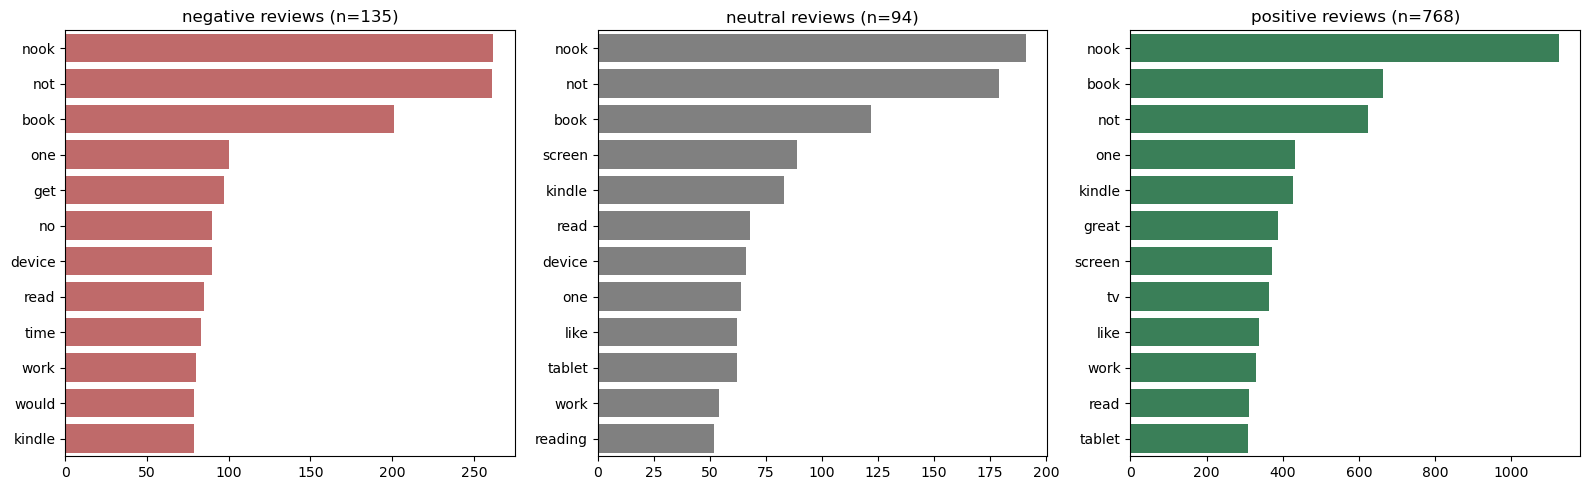

In [335]:
# language by sentiment
def top_by_group(mask, k=12):
    toks = [t for toks in df.loc[mask, 'processed_tokens'] for t in toks]
    return Counter(toks).most_common(k)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, lab in zip(axes, ['negative', 'neutral', 'positive']):
    w, c = zip(*top_by_group(df['sentiment_label'] == lab))
    sns.barplot(x=list(c), y=list(w), ax=ax, color={'negative': 'indianred', 'neutral': 'gray', 'positive': 'seagreen'}[lab])
    ax.set_title(f'{lab} reviews (n={int((df.sentiment_label == lab).sum())})')
plt.tight_layout(); plt.show()

In [336]:
# Distinctive words: TF-IDF mean by sentiment group
from sklearn.feature_extraction.text import TfidfVectorizer
tv = TfidfVectorizer(min_df=5, max_df=0.5)
M = tv.fit_transform(df['processed_text'])
terms = np.array(tv.get_feature_names_out())
for lab in ['negative', 'neutral', 'positive']:
    mean = np.asarray(M[(df['sentiment_label'] == lab).values].mean(axis=0)).ravel()
    print(f"{lab:9s}", ', '.join(terms[mean.argsort()[::-1][:12]]))

negative  not, nook, book, device, get, read, one, card, buy, kindle, tablet, screen
neutral   nook, not, book, tablet, work, screen, kindle, device, tv, one, mount, bought
positive  nook, tv, great, work, mount, cable, not, book, one, price, good, kindle


In [337]:
!pip install wordcloud

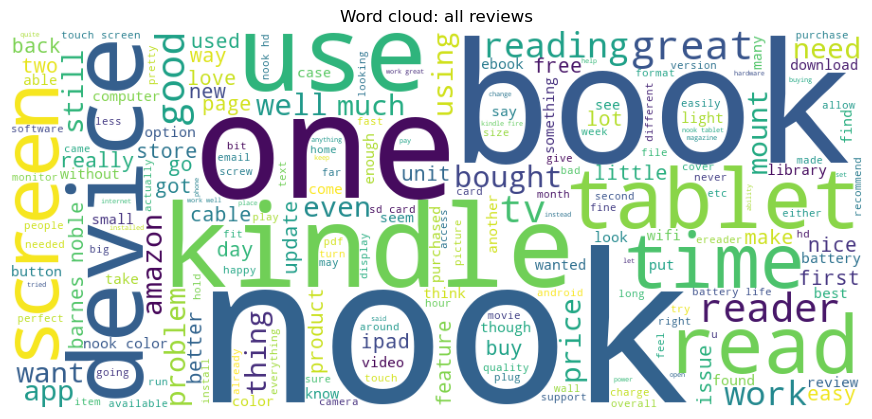

In [338]:
from wordcloud import WordCloud
wc = WordCloud(width=900, height=400, background_color='white').generate(' '.join(all_tokens))
plt.figure(figsize=(11, 5)); plt.imshow(wc); plt.axis('off'); plt.title('Word cloud: all reviews'); plt.show()

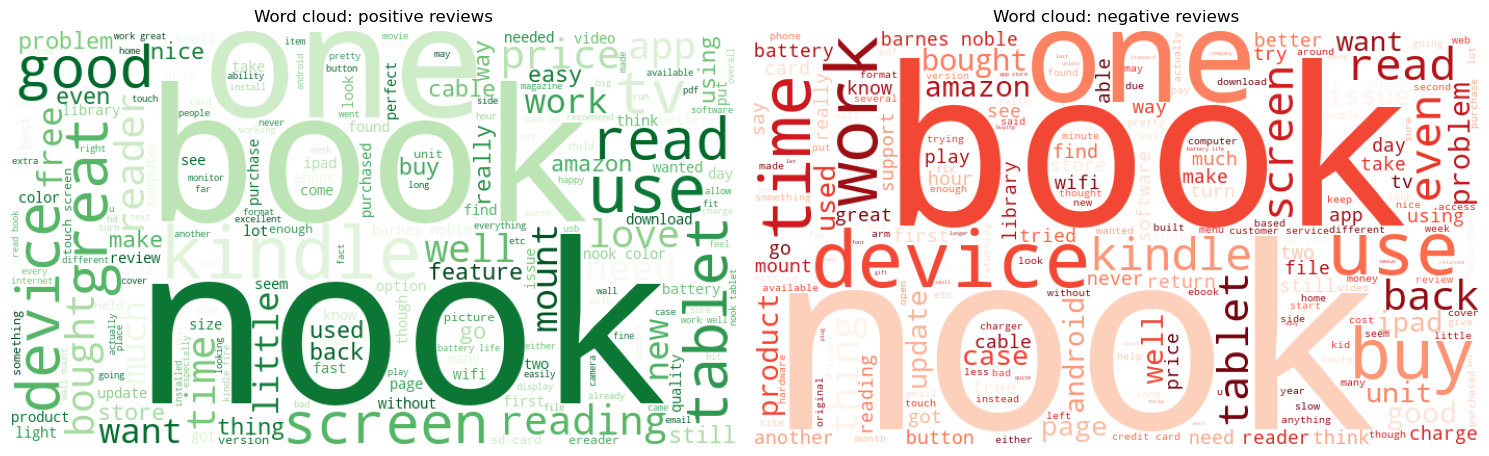

In [339]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, lab, cmap in zip(axes, ['positive', 'negative'], ['Greens', 'Reds']):
    txt = ' '.join(df.loc[df['sentiment_label'] == lab, 'processed_text'])
    wc = WordCloud(width=700, height=400, background_color='white', colormap=cmap).generate(txt)
    ax.imshow(wc)
    ax.axis('off')
    ax.set_title(f'Word cloud: {lab} reviews')
plt.tight_layout()
plt.show()

**Reflection (Part 1):**
During preprocessing I removed the standard English stopwords but deliberately kept “not”, “no” and “nor”. These words reverse meaning (“not good” versus “good”), so removing them would make negative reviews look positive. As a result, “not” (1,064) and “no” (408) became some of the most frequent tokens, and bigrams like “no problem” (53) show they carry sentiment. This also made “not” the top distinctive word for negative reviews.

The cleaned reviews are mostly about electronics. The most frequent words and phrases include nook, kindle, screen and tablet, plus bigrams such as “barnes noble” (166), “nook color” (135) and “battery life” (98). “tv”, “mount” and “cable” also rank high, so the dataset includes TV mounts and cables as well as e-readers. Positive language (“great”, “good”, “work great”, “work well”) is common, consistent with 5-star reviews being 58% of the data. Splitting by sentiment, positive reviews feature “great”, “work”, “mount”, “cable” and “price”, while negative reviews feature “not”, “device”, “card” and “buy”. Product words like nook and book appear in every group, so they do not separate sentiment.   
Trigrams show the complete product and feature names behind the bigrams: “nook simple touch” (37), “kindle fire hd” (8), “tv wall mount” (8) and “micro sd card” (28). They also show which topics customers discuss. Storage and expansion come up often (“micro sd card”, “sd card slot”), and so does app and content access (“google play store”, “access google play”, “access android market”, “adobe digital edition”). “Not big deal” (7) is a negation phrase that would have been lost if “not” had been removed as a stopword, so it supports the choice to keep it.

# Part 2 : Time Series

In [360]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings; warnings.filterwarnings('ignore')


In [341]:
# load dataset
df = pd.read_csv('amazon_reviews_lab.csv')
print(df.shape)
df.head()

(997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [342]:
# Convert the timestamp column to datetime format.
ts = pd.read_csv('amazon_reviews_lab.csv')
ts['timestamp'] = pd.to_datetime(ts['timestamp'])
print("Earliest:", ts['timestamp'].min().date(), "| Latest:", ts['timestamp'].max().date())
print("\nReviews per year:")
print(ts['timestamp'].dt.year.value_counts().sort_index().to_string())

Earliest: 2000-05-12 | Latest: 2014-07-17

Reviews per year:
timestamp
2000      1
2002      1
2005      2
2007      1
2008      3
2009      9
2010    131
2011    164
2012    200
2013    325
2014    160


In [343]:
ts = ts.set_index('timestamp').sort_index()
monthly_review_count = ts['rating'].resample('MS').count()
monthly_avg_rating = ts['rating'].resample('MS').mean()    # NaN for months with no reviews

print("Months in range:", len(monthly_review_count), "| months with zero reviews:", (monthly_review_count == 0).sum())
print("Months with zero reviews since 2010:", (monthly_review_count['2010':] == 0).sum())

Months in range: 171 | months with zero reviews: 103
Months with zero reviews since 2010: 0


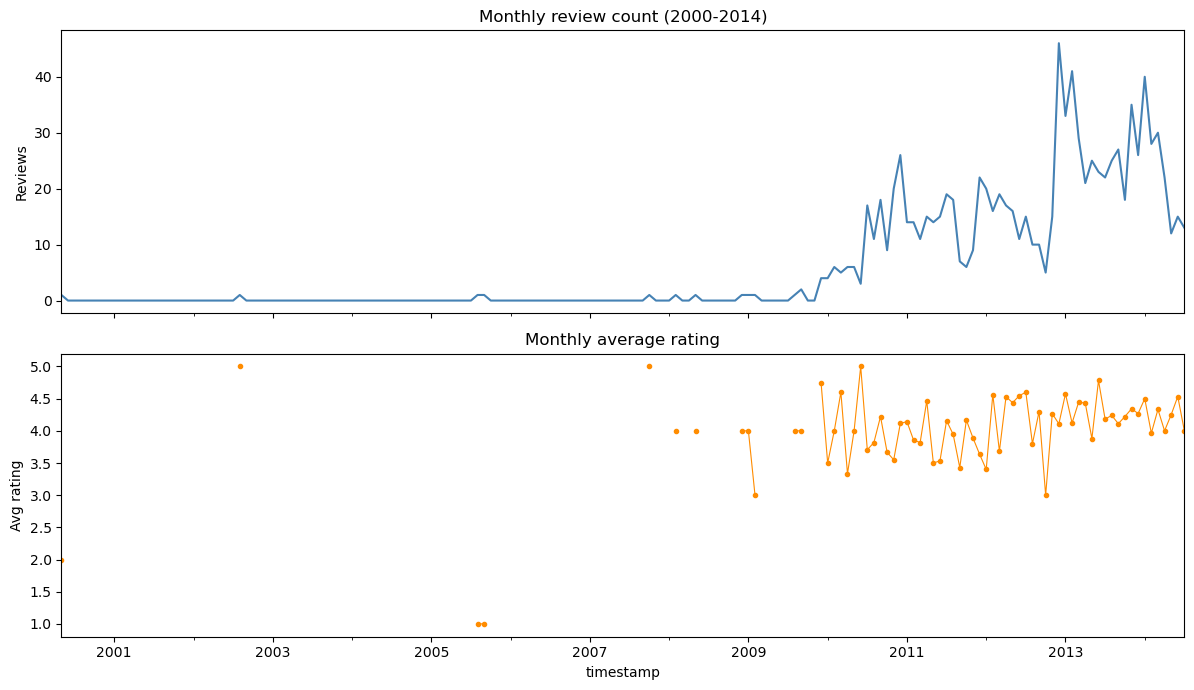

In [344]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly_review_count.plot(ax=ax[0], color='steelblue'); ax[0].set_title('Monthly review count (2000-2014)'); ax[0].set_ylabel('Reviews')
monthly_avg_rating.plot(ax=ax[1], marker='o', ms=3, lw=0.8, color='darkorange'); ax[1].set_title('Monthly average rating'); ax[1].set_ylabel('Avg rating')
plt.tight_layout(); plt.show()

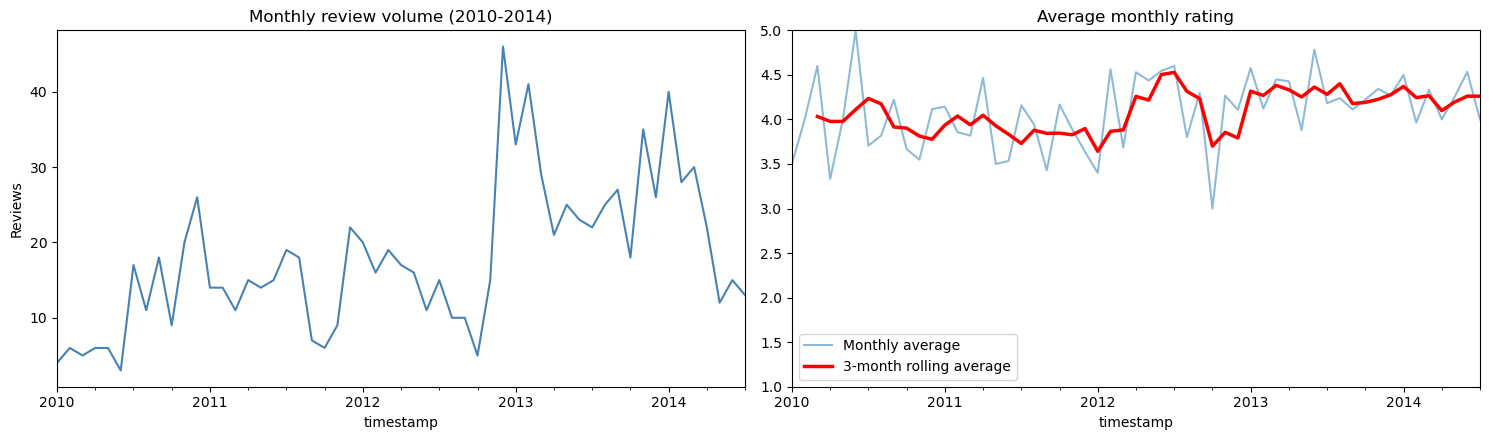

Peak month: 2012-12 with 46 reviews
Mean rating 2010-2014: 4.14


In [345]:
count_d = monthly_review_count['2010':]
rating_d = monthly_avg_rating['2010':]
rolling_avg_rating = rating_d.rolling(window=3).mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
count_d.plot(ax=ax[0], color='steelblue'); ax[0].set_title('Monthly review volume (2010-2014)'); ax[0].set_ylabel('Reviews')
rating_d.plot(ax=ax[1], alpha=0.5, label='Monthly average')
rolling_avg_rating.plot(ax=ax[1], lw=2.5, color='red', label='3-month rolling average')
ax[1].set_title('Average monthly rating'); ax[1].set_ylim(1, 5); ax[1].legend()
plt.tight_layout(); plt.show()
print("Peak month:", count_d.idxmax().strftime('%Y-%m'), "with", int(count_d.max()), "reviews")
print("Mean rating 2010-2014:", round(ts.loc['2010':, 'rating'].mean(), 2))

In [346]:
# stationarity, decompoase
def adf(series, name):
    s = series.dropna()
    stat, p = adfuller(s, autolag='AIC')[:2]
    print(f"{name:32s} ADF stat={stat:7.3f}  p={p:.4f}  -> {'stationary' if p < 0.05 else 'NON-stationary'}")

adf(count_d, 'Review count')
adf(np.log1p(count_d).diff(), 'Log review count, differenced')
adf(rating_d, 'Average rating')
adf(rating_d.diff(), 'Average rating, differenced')

Review count                     ADF stat= -1.021  p=0.7457  -> NON-stationary
Log review count, differenced    ADF stat= -4.363  p=0.0003  -> stationary
Average rating                   ADF stat= -1.169  p=0.6870  -> NON-stationary
Average rating, differenced      ADF stat= -7.073  p=0.0000  -> stationary


In [347]:
from statsmodels.tsa.stattools import kpss
import warnings

def kpss_test(series, name):
    s = series.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        stat, p = kpss(s, regression='c', nlags='auto')[:2]
    print(f"{name:32s} KPSS stat={stat:6.3f}  p={p:.4f}  -> {'stationary' if p > 0.05 else 'NON-stationary'}")

kpss_test(count_d, 'Review count')
kpss_test(np.log1p(count_d).diff(), 'Log review count, differenced')
kpss_test(rating_d, 'Average rating')
kpss_test(rating_d.diff(), 'Average rating, differenced')

Review count                     KPSS stat= 0.672  p=0.0161  -> NON-stationary
Log review count, differenced    KPSS stat= 0.118  p=0.1000  -> stationary
Average rating                   KPSS stat= 0.636  p=0.0194  -> NON-stationary
Average rating, differenced      KPSS stat= 0.201  p=0.1000  -> stationary


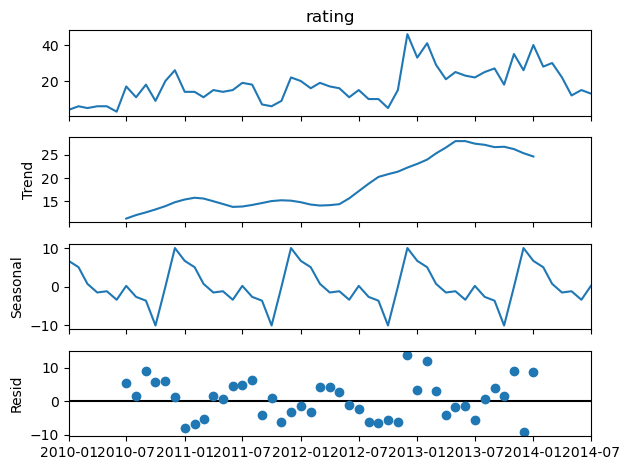

In [348]:
decomp = seasonal_decompose(count_d, model='additive', period=12)
decomp.plot(); plt.show()

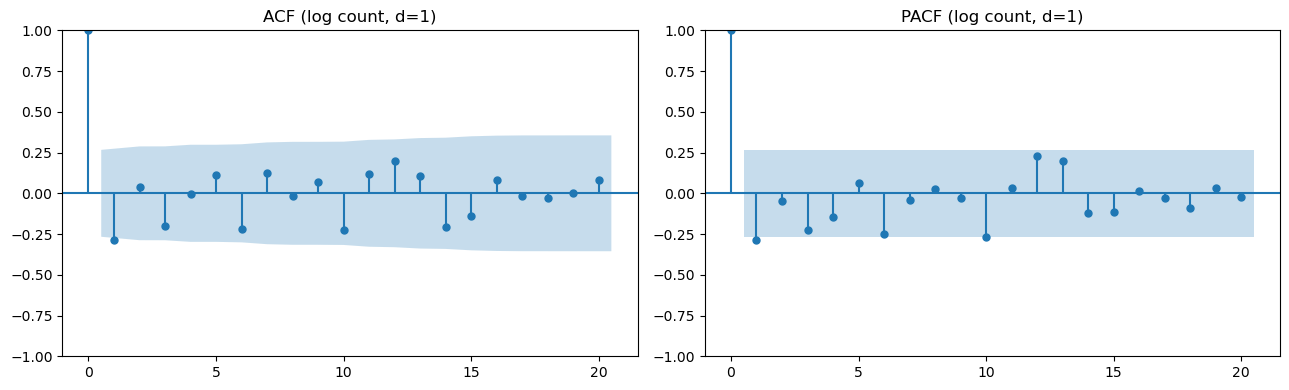

In [349]:
# ACF/PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stationary_series = np.log1p(count_d).diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(stationary_series, lags=20, ax=ax[0]);  ax[0].set_title('ACF (log count, d=1)')
plot_pacf(stationary_series, lags=20, ax=ax[1], method='ywm'); ax[1].set_title('PACF (log count, d=1)')
plt.tight_layout(); plt.show()

In [361]:
# ARIMA model comparison
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

y = np.log1p(count_d)          # log to stabilise the growing variance of the count series
h = 6
train, test = y.iloc[:-h], y.iloc[-h:]

rows = []
for p in range(0, 3):
    for q in range(0, 3):
        for d in (0, 1):
            try:
                m = ARIMA(train, order=(p, d, q)).fit()
                pred = np.expm1(m.forecast(h))
                rows.append({'order': (p, d, q), 'AIC': m.aic, 'BIC': m.bic,
                             'MAE': mean_absolute_error(np.expm1(test), pred),
                             'RMSE': np.sqrt(mean_squared_error(np.expm1(test), pred))})
            except Exception:
                pass
res = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
res.head(8)

,order,AIC,BIC,MAE,RMSE
0,"(1, 1, 1)",61.528799,67.142402,10.214179,11.864693
1,"(0, 1, 1)",61.713759,65.456161,14.142014,15.842871
2,"(0, 1, 2)",62.678297,68.291900,11.865107,13.658911
3,"(1, 1, 0)",62.815974,66.558376,16.226749,17.783348
4,"(2, 1, 1)",63.374430,70.859234,10.074684,11.700937
5,"(1, 1, 2)",63.439329,70.924133,10.131117,11.762325
6,"(1, 0, 0)",63.901727,69.577188,3.578173,4.145872
7,"(2, 1, 0)",64.629405,70.243008,16.062018,17.616320


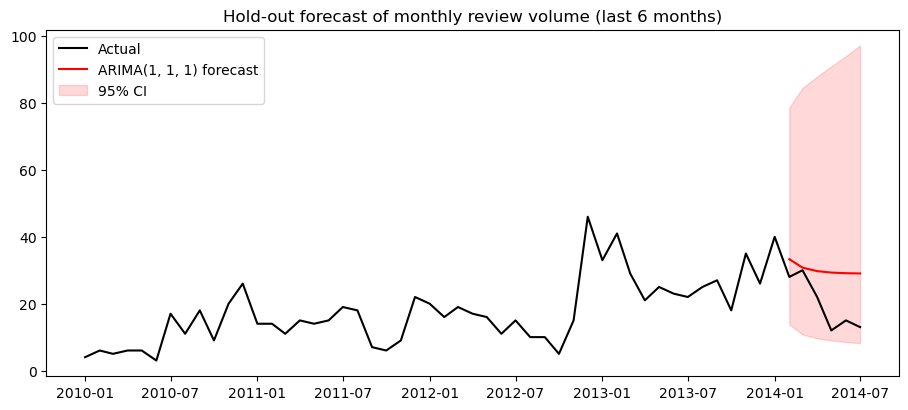

Best by AIC: (1, 1, 1)
MAE : 10.21
RMSE: 11.86


In [363]:
# Best model, forecast and metrics
best = res.iloc[0]['order']
model = ARIMA(train, order=best).fit()
fc = model.get_forecast(h)
pred = np.expm1(fc.predicted_mean); ci = np.expm1(fc.conf_int())

plt.figure(figsize=(11, 4.5))
plt.plot(count_d, label='Actual', color='black')
plt.plot(pred, label=f'ARIMA{best} forecast', color='red')
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color='red', alpha=0.15, label='95% CI')
plt.legend(); plt.title('Hold-out forecast of monthly review volume (last 6 months)'); plt.show()

print("Best by AIC:", best)
print("MAE :", round(mean_absolute_error(count_d.iloc[-h:], pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(count_d.iloc[-h:], pred)), 2))

      lb_stat  lb_pvalue
6    4.834679   0.565185
12  12.336371   0.419057


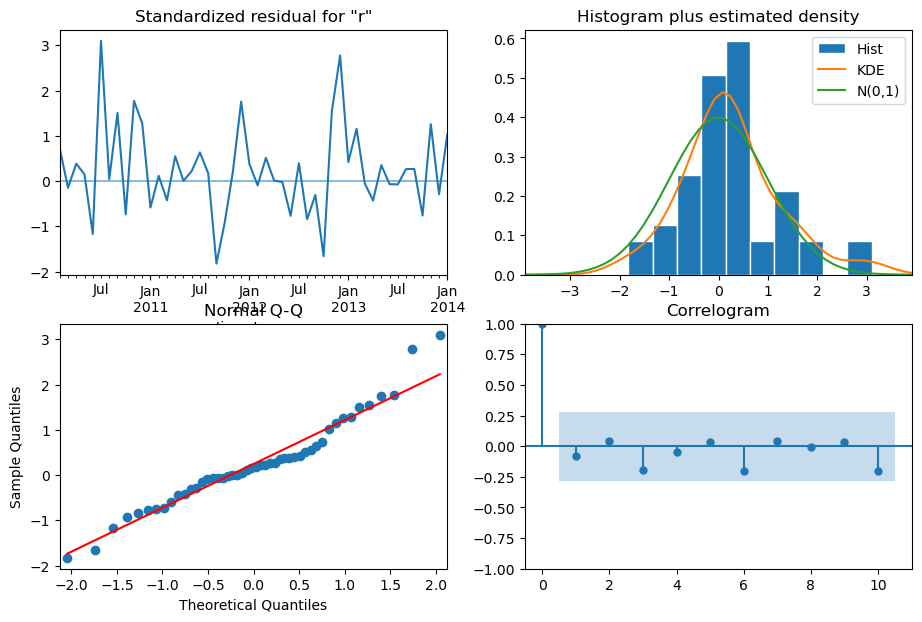

In [364]:
# Ljung-Box and diagnostics
from statsmodels.stats.diagnostic import acorr_ljungbox
resid = model.resid.iloc[1:]
print(acorr_ljungbox(resid, lags=[6, 12]))
model.plot_diagnostics(figsize=(11, 7)); plt.show()

**Reflection (Part 2)**   
Review activity is almost absent before 2010 (only 17 reviews), then grows from 131 in 2010 to 325 in 2013, with a peak month of December 2012 (46 reviews), probably from holiday purchases. 2014 runs only through July: 160 reviews in 7 months, about 23 a month versus about 27 a month in 2013. The average rating is high and rises slowly: the yearly mean goes from about 3.9 in 2010 to 4.3 in 2013, and the mean over 2010-2014 is 4.14. Single months are noisy (ranging from 3.0 to 5.0), so the 3-month rolling average, which stays between about 3.6 and 4.5, shows the trend better.

The ADF test shows review count (p = 0.75) and average rating (p = 0.69) are non-stationary. Both become stationary after differencing (p = 0.0003 for the log counts and p < 0.0001 for ratings), which supports d = 1. KPSS, whose null hypothesis is the opposite of ADF’s, gave the same answer: review count (p = 0.016) and average rating (p = 0.019) are non-stationary, while both differenced series are not rejected as stationary (p = 0.10). Two tests that start from opposite hypotheses agreeing is stronger evidence for d = 1.

The ACF and PACF of the differenced log counts each show one negative spike at lag 1 (about -0.3) and little else, with no spike at lag 12, so there is no strong seasonal pattern. This suggests a low-order model such as ARIMA(0,1,1) or (1,1,1), which matches the models with the lowest AIC in the grid search. Among the ARIMA models, (1,1,1) had the lowest AIC (61.5), with MAE 10.2 and RMSE 11.9 on the 6-month hold-out. The (1,0,0) model had a higher AIC (63.9) but a much lower hold-out error (MAE 3.6, RMSE 4.1). AIC values aren’t strictly comparable across different differencing orders, so the hold-out error is the better guide here. In practice, an MAE of about 4 reviews against a typical month of 20 to 30 is usable for rough staffing or inventory planning, but with only about 55 monthly points the forecast is a planning range, not a precise prediction.  
A Ljung-Box test on the residuals of the ARIMA(1,1,1) model gave p = 0.57 at lag 6 and p = 0.42 at lag 12, so there is no evidence of leftover autocorrelation and the residuals look like white noise

# Part 3 : Neural Networks

In [352]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
np.random.seed(42); tf.random.set_seed(42)

In [353]:
# load dataset
df = pd.read_csv('amazon_reviews_lab.csv')
print(df.shape)
df.head()

(997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [354]:
nn_df = pd.read_csv('amazon_reviews_lab.csv')
X = nn_df['review_text'].astype(str)
y = nn_df['rating'] - 1          # ratings 1-5 -> classes 0-4
print(y.value_counts().sort_index())

rating
0     87
1     48
2     94
3    188
4    580
Name: count, dtype: int64


In [355]:
# Split,then TF-IDF (fit on train only, no leakage)
X_train_txt, X_test_txt, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), stop_words='english', min_df=2)
X_train = vectorizer.fit_transform(X_train_txt).toarray().astype('float32')
X_test = vectorizer.transform(X_test_txt).toarray().astype('float32')
print("Train:", X_train.shape, "Test:", X_test.shape)
# one-hot encode the target
y_train_oh = keras.utils.to_categorical(y_train, num_classes=5)
y_test_oh = keras.utils.to_categorical(y_test, num_classes=5)

Train: (797, 2000) Test: (200, 2000)


**Architecture choices.** The input is 2,000 TF-IDF features (unigrams and bigrams). The network is a multi-layer perceptron with two hidden layers (64 units, then 32) that taper toward the 5 output classes, 130,309 trainable parameters in total.

**ReLU in the hidden layers:** it is cheap to compute and avoids the vanishing-gradient problem of sigmoid or tanh.  
**Softmax output** with categorical cross-entropy: the five star ratings are mutually exclusive classes, so the output is a probability distribution over them.    
**Dropout** (0.5 after the first layer, 0.3 after the second): with only about 800 training reviews and 2,000 features the network overfits quickly, so dropout acts as regularization.   
Adam, learning rate 5e-4: the default optimizer, with RMSprop and SGD with momentum compared in the model comparison table   
**Class weights:** 58% of reviews are 5 stars, so rarer ratings are weighted more heavily to stop the model from always predicting 5.  
**Early stopping** on validation loss (patience 5): training stops once validation loss stops improving, and the best weights are restored.

In [356]:
# Build Model
keras.utils.set_random_seed(42)
def build_model(dropout1=0.5, dropout2=0.3, lr=1e-3, optimizer='adam'):
    m = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(dropout1),
        layers.Dense(32, activation='relu'),
        layers.Dropout(dropout2),
        layers.Dense(5, activation='softmax')])
    opt = {'adam': keras.optimizers.Adam(lr), 'rmsprop': keras.optimizers.RMSprop(lr),
           'sgd': keras.optimizers.SGD(lr * 10, momentum=0.9)}[optimizer]
    m.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return m

cw = compute_class_weight('balanced', classes=np.arange(5), y=y_train.values)
cw = dict(enumerate(cw)); print("Class weights (rating -> weight):", {k + 1: round(float(v), 2) for k, v in cw.items()})
model = build_model(lr=5e-4)
model.summary()

Class weights (rating -> weight): {1: 2.28, 2: 4.19, 3: 2.13, 4: 1.06, 5: 0.34}


Model: "sequential_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_159 (Dense)                    │ (None, 64)                  │         128,064 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_106 (Dropout)                │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_160 (Dense)                    │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_107 (Dropout)                │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_161 (Dense)                    │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,309 (509.02 KB)

 Trainable params: 130,309 (509.02 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 31 epochs


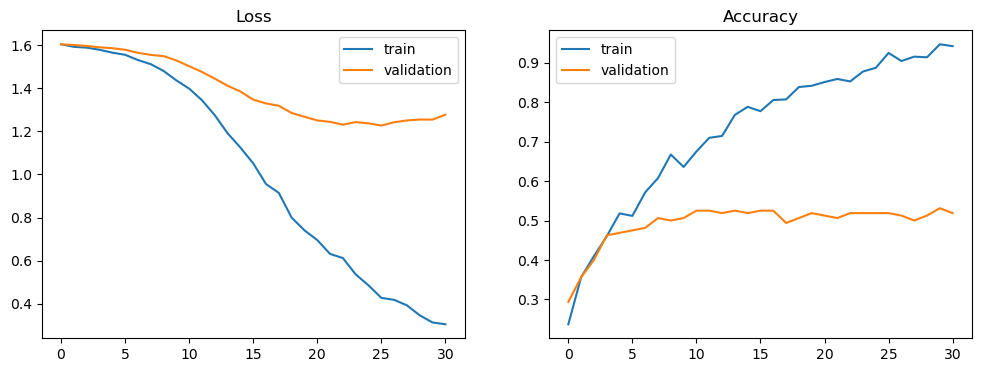

In [357]:
# Train
keras.utils.set_random_seed(42)
early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train_oh, validation_split=0.2, epochs=50, batch_size=32,
                    class_weight=cw, callbacks=[early], verbose=0)
print("Stopped after", len(history.history['loss']), "epochs")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].legend(); plt.show()

Test accuracy: 0.5450 | Test loss: 1.2665
Majority-class baseline accuracy: 0.58

              precision    recall  f1-score   support

           1       0.39      0.41      0.40        17
           2       0.20      0.10      0.13        10
           3       0.22      0.11      0.14        19
           4       0.27      0.21      0.24        38
           5       0.66      0.78      0.72       116

    accuracy                           0.55       200
   macro avg       0.35      0.32      0.33       200
weighted avg       0.50      0.55      0.51       200



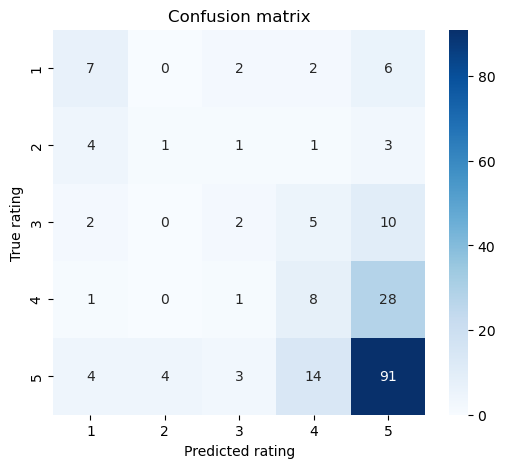

In [358]:
# evaluate on test set
test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")
print("Majority-class baseline accuracy:", round((y_test == y_train.mode()[0]).mean(), 4))
print()
print(classification_report(y_test + 1, y_pred + 1, zero_division=0))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test + 1, y_pred + 1), annot=True, fmt='d', cmap='Blues',
            xticklabels=range(1, 6), yticklabels=range(1, 6))
plt.xlabel('Predicted rating'); plt.ylabel('True rating'); plt.title('Confusion matrix'); plt.show()

In [359]:
# optimizer & class weights
configs = {
    'Adam, no class weights': dict(optimizer='adam', lr=5e-4),
    'Adam + class weights': dict(optimizer='adam', lr=5e-4, cw=True),
    'RMSprop + class weights': dict(optimizer='rmsprop', lr=5e-4, cw=True),
    'SGD (momentum) + class weights': dict(optimizer='sgd', lr=5e-4, cw=True),
    'Adam + cw, low dropout': dict(optimizer='adam', lr=5e-4, cw=True, dropout1=0.1, dropout2=0.1),
}
rows = []
for name, cfg in configs.items():
    cfg = dict(cfg); use_cw = cfg.pop('cw', False)
    tf.random.set_seed(42)
    m = build_model(**cfg)
    h = m.fit(X_train, y_train_oh, validation_split=0.2, epochs=50, batch_size=32, verbose=0,
              class_weight=cw if use_cw else None,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
    p = m.predict(X_test, verbose=0).argmax(axis=1)
    rows.append({'model': name, 'epochs': len(h.history['loss']),
                 'train_acc': h.history['accuracy'][-1], 'val_acc': h.history['val_accuracy'][-1],
                 'test_acc': accuracy_score(y_test, p), 'macro_F1': f1_score(y_test, p, average='macro')})
pd.DataFrame(rows).round(3)

,model,epochs,train_acc,val_acc,test_acc,macro_F1
0,"Adam, no class weights",20,0.760,0.556,0.575,0.157
1,Adam + class weights,32,0.932,0.544,0.520,0.311
2,RMSprop + class weights,43,0.854,0.556,0.520,0.337
3,SGD (momentum) + class weights,11,0.264,0.144,0.210,0.152
4,"Adam + cw, low dropout",22,0.989,0.575,0.555,0.285


###### Class weights penalize mistakes on rare ratings more, so the model stops defaulting to 5 stars

**Reflection (Part 3)**  
The class-weighted neural network reached 54.5% test accuracy, below the 58% majority-class baseline of always predicting 5 stars, so accuracy alone is misleading. Class weighting improved the balance across ratings: in the model comparison, macro-F1 rose from 0.157 (unweighted Adam) to 0.311 (class-weighted Adam), at some cost to accuracy (0.575 to 0.520).

The model predicted 5-star reviews best (F1 0.72), followed by 1-star (0.40) and 4-star (0.24). Ratings of 2 and 3 stars were hardest (F1 0.13 and 0.14) because they are rare. The confusion matrix shows the main weakness: the model leans toward the top ratings. Of the 46 reviews rated 1 to 3 stars, 19 were predicted as 5 stars, and 28 of the 38 four-star reviews were also predicted as 5. Only 1 of the 10 two-star reviews and 2 of the 19 three-star reviews were classified correctly. The 5-star class was right 91 times out of 116.

The results show overfitting. Early stopping ended the main model’s training after 31 epochs and restored the best weights. In the comparison, class-weighted Adam reached 0.932 training accuracy against only 0.544 validation accuracy. Optimizer and dropout choices changed the results. RMSprop gave the highest macro-F1 (0.337) with the same test accuracy as Adam (0.520), and SGD with momentum underfit, reaching only 0.264 training accuracy, 0.210 test accuracy and 0.152 macro-F1. Lower dropout pushed training accuracy to 0.989 without improving the result (0.555 test accuracy, 0.285 macro-F1), a sign the network memorizes the training set when it is less regularized. With only 200 test reviews, differences of a few points are within noise. With only about 800 training reviews and 2,000 TF-IDF features, overfitting is expected.

To improve it, I would collect more data, use pretrained word embeddings, compare against a TF-IDF logistic regression, or group ratings into negative, neutral and positive using sentiment_label